# Kernel ICL transience with the channel probe: paper figures

Loads the runs written by `rf_u_shape.ipynb` and draws, for each $T$, two panels on one $n$ axis:

- **top** -- the measured test error against the samples seen, with the dMMSE and Ridge oracles;
- **bottom** -- what causes its fall and rise: the channel probe's implemented fraction of each family
  group (`TU.PROBE_GROUPS`). 0 before a family is learned, 1 once the model carries all of it.

The runs come from the per-run checkpoints (`rf_u_shape_{tag}_T{T}_t{trial}.pt`), which hold every run
that started; a summary pickle only has what one session finished. Each trial draws its own task pool, so
the error curves are aligned on the dMMSE as in the other figure notebooks (`ALIGN`). The implemented
fractions are already relative to each trial's own pool and need no alignment. Bands are $\pm 1$
standard deviation across trials (none with one trial).

## Colab setup

In [3]:
from google.colab import drive
drive.mount('/content/drive')

import sys, os, subprocess

GIT_USER = "JoeyTurn"
GIT_REPO = "kernels_can_icl"
REPO_DIR = f"/content/{GIT_REPO}"

if not os.path.exists(REPO_DIR):
    r = subprocess.run(["git", "clone",
                        f"https://github.com/{GIT_USER}/{GIT_REPO}.git", REPO_DIR],
                       capture_output=True, text=True)
    if r.returncode != 0:
        raise RuntimeError(r.stderr)
else:
    # Re-running the cell pulls latest changes instead of failing on "already exists"
    subprocess.run(["git", "-C", REPO_DIR, "pull"], check=True)

sys.path.insert(0, REPO_DIR)
sys.path.insert(0, f"{REPO_DIR}/expts/rf_scaling")

RESULTPATH = "/content/drive/MyDrive/results"
os.environ["RESULTPATH"] = RESULTPATH
os.makedirs(RESULTPATH, exist_ok=True)

if not os.path.exists("/content/expt-core"):
    subprocess.run(["git", "clone", "https://github.com/dkarkada/expt-core.git",
                    "/content/expt-core"], check=True)

sys.path.insert(0, "/content/expt-core")
from misc import rcsetup
rcsetup()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GitHub PAT: ··········


In [4]:
import os, sys, glob, pickle
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import ticker

if os.path.exists("/content/kernels_can_icl"):
    # Colab: re-add the paths in case the runtime was restarted after the setup cell
    for p in ("/content/kernels_can_icl", "/content/kernels_can_icl/expts/rf_scaling", "/content/expt-core"):
        if p not in sys.path:
            sys.path.insert(0, p)
    RESULTPATH = os.environ.get("RESULTPATH", "/content/drive/MyDrive/results")
else:
    ROOT = Path.cwd()
    while ROOT != ROOT.parent and not (ROOT / "kernels_can_icl" / "__init__.py").exists():
        ROOT = ROOT.parent
    sys.path.insert(0, str(ROOT))
    sys.path.insert(0, str(ROOT / "expts" / "rf_scaling"))
    sys.path.insert(0, str(ROOT.parent / "expt-core"))
    RESULTPATH = str(ROOT / "expts" / "rf_scaling" / "results")

try:
    from misc import rcsetup
    rcsetup()
except ImportError:                     # the same settings as expt-core's misc.rcsetup
    plt.rc("figure", dpi=120, facecolor=(1, 1, 1))
    plt.rc("font", family="stixgeneral", size=12)
    plt.rc("axes", facecolor=(1, .99, .95), titlesize=12)
    plt.rc("mathtext", fontset="cm")
    plt.rc("pdf", fonttype=42)
    plt.rc("ps", fonttype=42)
print("RESULTPATH:", RESULTPATH)

RESULTPATH: /content/drive/MyDrive/results


## Settings

`RUNS` maps a legend label to a source of runs: `None` takes the newest set of per-run checkpoints, a
string picks a tag (or any part of one), or reads a `*_summary.pkl` if it ends in `.pkl`. One figure per T
in `CURVE_TS`.

In [5]:
RUNS         = {"Random Features\n Network": None}   # label -> None (newest set of per-run checkpoints), a tag or
                                      #   part of one, or a path to a *_summary.pkl
CURVE_TS     = [8]                    # one figure per T
SIDE         = "ood"                  # the top panel's error: "ood" or "id"
YSCALE       = "linear"               # "log" as in fig 2
YLIM         = {0.3, 1.15}                     # e.g. {"ood": (0.3, 1.15)}; default fits the curve and the oracles
SD_BAND      = True                   # +/- 1 standard deviation across trials (none with 1 trial)
ORA_BAND     = True                   # shade that spread on the oracle lines too
ALIGN        = None                   # put every trial on one pool's level before averaging: shift trial i
                                      #   by Delta_i = dMMSE_i - dMMSE_baseline (None = raw mean)
ALIGN_BASE   = "first"                # the baseline pool: the "first" trial, or the "mean" over trials
LEGEND_LOC   = "lower left"           # a lower legend sits just above an oracle line along the bottom
FONTSIZE     = 15                     # tick labels and legend; axis labels +2, the T label +6
T_LABEL      = True                   # the in-plot "T=..." label
TOP_FREE     = 0.25                   # keep this much of the top panel clear under the T label and legend
XLABEL       = r"Samples Seen $n$"
PROBE_SHOW   = None                   # which TU.PROBE_GROUPS to draw (None = all), by their labels
PROBE_LABELS = {"mean  (q)": r"$\phi_1$ (Mean task)", "ICL  (x y q)": r"$\phi_3$ ($\beta$ estimate)",
                "kappa_3  (y^2 x^3 q)": r"$\psi_5$ (Higher order term)", "other degree 5": r"Other $\psi_5$"} #$\kappa_3$
PROBE_LEGEND = "center left"
PROBE_YLIM   = None                   # e.g. (-0.05, 1.25); the noisy mean fraction can otherwise set it
HEIGHT_RATIO = 0.8                    # bottom panel height relative to the top

In [6]:
import re

CKPT_RE = re.compile(r"^rf_u_shape_(.*)_T(\d+)_t(\d+)\.pt$")


def ckpt_groups(resultpath):
    """{tag: [(T, trial, path)]} over the per-run checkpoints in resultpath.

    One checkpoint per (T, seed), written while the run trains, so these cover every run that started
    -- including ones a later session never wrote into a summary pickle, and ones still going.
    """
    groups = {}
    for path in sorted(glob.glob(os.path.join(resultpath, "rf_u_shape_*_T*_t*.pt"))):
        m = CKPT_RE.match(os.path.basename(path))
        if m:
            groups.setdefault(m.group(1), []).append((int(m.group(2)), int(m.group(3)), path))
    return groups


def load_ckpts(entries):
    """(records, info) from per-run checkpoints, in the same shape as a summary pickle's records."""
    import torch                            # only the checkpoints need it
    records, info = [], {}
    for T, trial, path in entries:
        st = torch.load(path, map_location="cpu", weights_only=False)
        fp = st["fingerprint"]
        records.append(dict(T=T, trial=trial, seed=fp.get("seed"), step=int(st["step"]),
                            eta=float(st.get("eta_run", fp.get("eta", float("nan")))),
                            curve=st["curve"], **st["ref"]))
        info = dict(P=fp.get("P", fp.get("M")), batch=fp["batch"], width=fp["width"],
                    eta=fp.get("eta"))
    return records, info


def load_summary(path):
    """(records, info) from a summary pickle: only the runs one session finished."""
    with open(path, "rb") as f:
        S = pickle.load(f)
    return S["records"], dict(P=S.get("P", S.get("M")), batch=S["batch"], width=S["width"],
                              eta=S.get("eta"))


def load_sgd(entry, resultpath):
    """(label source, records, info, tag) for one RUNS entry.

    None picks the newest set of per-run checkpoints (preferring full runs over _smoke ones), which is
    the complete picture; a tag, or any part of one, picks that set; a path to a *_summary.pkl reads
    the pickle instead.
    """
    groups = ckpt_groups(resultpath)
    if isinstance(entry, str) and entry.endswith(".pkl"):
        path = entry if os.path.isabs(entry) or os.path.exists(entry) else os.path.join(resultpath, entry)
        recs, info = load_summary(path)
        return os.path.basename(path), recs, info,             os.path.basename(path).removeprefix("rf_u_shape_").removesuffix("_summary.pkl")
    if isinstance(entry, str):
        hits = [t for t in groups if entry in t]
        if not hits:
            raise FileNotFoundError(f"no checkpoints matching {entry!r} in {resultpath}"
                                    f" (tags: {sorted(groups)})")
        tag = max(hits, key=lambda t: max(os.path.getmtime(e[2]) for e in groups[t]))
    elif groups:
        full = [t for t in groups if "_smoke" not in t] or list(groups)
        tag = max(full, key=lambda t: max(os.path.getmtime(e[2]) for e in groups[t]))
    else:                                   # no checkpoints: fall back to the newest summary
        paths = glob.glob(os.path.join(resultpath, "rf_u_shape_*_summary.pkl"))
        if not paths:
            raise FileNotFoundError(f"no SGD checkpoints or summaries in {resultpath}")
        full = [p for p in paths if "_smoke" not in os.path.basename(p)] or paths
        return load_sgd(max(full, key=os.path.getmtime), resultpath)
    recs, info = load_ckpts(groups[tag])
    return f"{len(groups[tag])} checkpoints", recs, info, tag


runs, tags = [], []
for label, entry in RUNS.items():
    src, records, info, tag = load_sgd(entry, RESULTPATH)
    runs.append((label, records))
    tags.append(tag)
    print(f"{label}: {tag}  ({src})")
    print(f"    features {info['P']:,}   batch {info['batch']}   width {info['width']:.3g}"
          + (f"   eta {info['eta']:.3g}" if info.get("eta") else ""))
    for T in sorted({r["T"] for r in records}):
        rs = sorted((r for r in records if r["T"] == T), key=lambda r: r.get("trial", 0))
        # runs stopped at different points would be averaged over different n, so show where each ended
        print(f"    T={T}: " + ", ".join(
            f"seed {r.get('trial')} to n={max(c['n'] for c in r['curve']):,}" for r in rs if r["curve"]))

TAG = tags[0]

Random Features
 Network: d4p5e0.05_M8192_b1024_w1.1  (3 checkpoints)
    features 8,192   batch 1024   width 4.85
    T=8: seed 0 to n=3,427,969,024, seed 1 to n=3,427,969,024, seed 2 to n=3,427,969,024


## Figure

In [7]:
# figure 2's palette, in series order
STYLES = [("#0F3087", "o"), ("#6C63F0", "s"), ("#D97706", "^"), ("#C2185B", "D"), ("#2E7D32", "v")]
ORACLES = (("dmmse", "Memorizing Solution", "#DC143C", 2.0), ("ridge", "Generalizing Solution", "black", 2.8))
SIDE_NAME = {"ood": f"Novel Tasks\n", "id": "Training Tasks"}


def pool_offsets(records, T, side, align="dmmse", base="first"):
    """{trial: Delta_i} putting every trial's pool on one baseline level, and that baseline's dMMSE.

    Each trial draws its own task pool (the seed is keyed on T *and* the trial), and at small T the pool
    sets the level of the whole curve -- pools whose dMMSE differs by 0.1 shift their curves by about
    that much. Averaging the raw curves then inflates the band and flattens the dip. So everything a
    trial produces is shifted by Delta_i = dMMSE_i - dMMSE_baseline before it is averaged, which puts
    every pool on the baseline pool's level; the plotted dMMSE line lands exactly on that baseline.
    align=None turns this off (raw averaging). base: "first" trial's pool, or the "mean" over pools.
    """
    recs = sorted((r for r in records if r["T"] == T), key=lambda r: r.get("trial", 0))
    dm = [r["oracles"][f"dmmse_{side}"] for r in recs]
    if not dm:
        return {}, np.nan
    if not align:
        return {}, float(np.mean(dm))
    b = dm[0] if base == "first" else float(np.mean(dm))
    return {r.get("trial", i): d - b for i, (r, d) in enumerate(zip(recs, dm))}, b


def curve_stats(records, T, side, band=True, offs=None):
    """(n, mean, sd) of the measured curve at task diversity T, over trials, each shifted onto the
    baseline pool by `offs` (see pool_offsets). sd is the sample standard deviation across trials
    (never the standard error); 0 with one trial or band=False."""
    offs = offs or {}
    recs = [r for r in records if r["T"] == T and r.get("curve")]
    ns = sorted({c["n"] for r in recs for c in r["curve"]})
    m, s = [], []
    for n in ns:
        v = np.array([c[side] - offs.get(r.get("trial", 0), 0.0)
                      for r in recs for c in r["curve"] if c["n"] == n], float)
        v = v[np.isfinite(v)]
        m.append(v.mean() if v.size else np.nan)
        s.append(v.std(ddof=1) if band and v.size > 1 else 0.0)
    return np.array(ns, float), np.array(m), np.array(s)


def oracle_stats(records, T, key, side, offs=None, band=True):
    """(mean, sd) of an oracle ('dmmse' or 'ridge') over trials, on the same shifted pools as the
    curves. Note that aligning on the dMMSE makes every trial's dMMSE the baseline, so its sd is then
    exactly 0 -- the pool spread has moved into the curves, which are now read against their own pool."""
    offs = offs or {}
    v = np.array([r["oracles"][f"{key}_{side}"] - offs.get(r.get("trial", 0), 0.0)
                  for r in records if r["T"] == T], float)
    return float(v.mean()), float(v.std(ddof=1)) if band and v.size > 1 else 0.0


def theory_curve(records, T, side, offs=None):
    """(n, trial mean) of the theory curve record["pred"], shifted like the curves; None if absent."""
    offs = offs or {}
    recs = [r for r in records if r["T"] == T and r.get("pred")]
    if not recs:
        return None
    n = np.asarray(recs[0]["pred"]["n"], float)
    ys = [np.asarray(r["pred"][side], float) - offs.get(r.get("trial", 0), 0.0)
          for r in recs if len(r["pred"][side]) == len(n)]
    return n, np.mean(ys, 0)


def log_ticks(lo, hi, max_ticks=7):
    """Round tick values for a log axis: the finest of {1,1.2,1.5,2,3,4,5,6,8}, {1,2,3,5}, {1,2,5}, {1}
    per decade that puts at most max_ticks inside [lo, hi]."""
    decades = 10.0 ** np.arange(np.floor(np.log10(lo)), np.ceil(np.log10(hi)) + 1)
    for mant in ((1, 1.2, 1.5, 2, 3, 4, 5, 6, 8), (1, 2, 3, 5), (1, 2, 5), (1,)):
        vals = [float(f"{m * d:.6g}") for d in decades for m in mant]
        vals = [v for v in vals if lo <= v <= hi]
        if 2 <= len(vals) <= max_ticks:
            return vals
    return None


def default_ylim(ax, xys, yscale, top_free, x_from=0.38):
    """y-limits that fit everything drawn, raised if needed so the top `top_free` of the axis is
    clear of data right of x-fraction `x_from` -- where the T label and an upper-right legend sit.
    The x-limits must already be set (call after plotting)."""
    log = yscale == "log"
    ok = lambda y: np.isfinite(y) & (y > 0) if log else np.isfinite(y)
    ys = np.concatenate([y[ok(y)] for _, y in xys])
    if log:
        lo, hi = ys.min() / 1.1, ys.max() * 1.08
    else:
        pad = 0.06 * (ys.max() - ys.min())
        lo, hi = ys.min() - pad, ys.max() + pad
    x0, x1 = np.log10(ax.get_xlim())
    under = [y[ok(y) & ((np.log10(n) - x0) / (x1 - x0) >= x_from)] if n is not None else y[ok(y)]
             for n, y in xys]
    top = max((u.max() for u in under if u.size), default=None)
    if top is not None and 0 < top_free < 1:
        if log:
            hi = max(hi, lo * (top / lo) ** (1.0 / (1.0 - top_free)))
        else:
            hi = max(hi, lo + (top - lo) / (1.0 - top_free))
    return lo, hi


def finish_panel(ax, xys, side, yscale, ylim_side, top_free, fontsize, xlabel, label, floor_y):
    """Shared panel cosmetics: y-limits, round log ticks, tick and label sizes, and the in-plot label.
    Returns the axes-fraction height of floor_y, which is what a lower legend has to clear."""
    ax.set_yscale(yscale)
    lo, hi = ylim_side if ylim_side else default_ylim(ax, xys, yscale, top_free)
    ax.set_ylim(lo, hi)
    if yscale == "log":
        vals = log_ticks(lo, hi)
        if vals:
            ax.yaxis.set_major_locator(ticker.FixedLocator(vals))
            ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda v, _: f"{v:g}"))
            ax.yaxis.set_minor_locator(ticker.LogLocator(subs="all"))
            ax.yaxis.set_minor_formatter(ticker.NullFormatter())
    ax.tick_params(which="major", length=6, width=1.0, labelsize=fontsize)
    ax.tick_params(which="minor", length=3.5, width=0.8)
    ax.grid(axis="x", which="major", alpha=0.15, lw=0.8)
    if label:
        ax.text(0.5, 0.965, label, transform=ax.transAxes, ha="center", va="top",
                fontsize=fontsize + 6)
    ax.set_xlabel(xlabel, fontsize=fontsize)
    ax.set_ylabel(f"{SIDE_NAME[side]} Test MSE", fontsize=fontsize)
    return ax.transAxes.inverted().transform(ax.transData.transform((ax.get_xlim()[0], floor_y)))[1]


def place_legend(ax, floor_frac, legend_loc, fontsize):
    """The legend, kept off an oracle line that runs along the bottom of the axes."""
    leg = dict(loc=legend_loc, framealpha=1.0, fontsize=fontsize)
    if legend_loc.startswith("lower") and 0.0 <= floor_frac < 0.2:
        leg["bbox_to_anchor"] = ({"left": 0.0, "center": 0.5, "right": 1.0}[legend_loc.split()[-1]],
                                 floor_frac + 0.01)
    ax.legend(**leg)


def draw_n_panel(ax, runs, T, side, yscale="log", ylim=None, band=True, theory=False,
                 legend_loc="upper right", xlabel="$n$", top_free=0.25, ms=6, fontsize=15, t_label=True,
                 align="dmmse", align_base="first", oracle_band=True):
    """One n-curve panel on `ax`: each run's measured curve, the dMMSE and Ridge oracles, and the
    theory curve if theory=True. Returns the axes-fraction height of the lowest oracle line, for
    place_legend. Arguments as plot_fig2 (ylim is the {side: (lo, hi)} dict)."""
    ylim = ylim or {}
    if not (t_label or legend_loc.startswith("upper")):
        top_free = 0.0                      # nothing sits along the top to keep clear of
    ref = next(recs for _, recs in runs if any(r["T"] == T for r in recs))
    xys = []                                # (n, y) of everything drawn; n=None for the oracle lines
    for k, (label, records) in enumerate(runs):
        offs, _ = pool_offsets(records, T, side, align, align_base)
        n, m, s = curve_stats(records, T, side, band, offs)
        if not len(n):
            continue
        col, mk = STYLES[k % len(STYLES)]
        if np.any(s > 0):
            ax.fill_between(n, m - s, m + s, color=col, alpha=0.2, lw=0, zorder=3)
        ax.plot(n, m, "-", marker=mk, color=col, lw=2.0, ms=ms, label=label, zorder=4)
        xys += [(n, m - s), (n, m + s)]
    roffs, _ = pool_offsets(ref, T, side, align, align_base)
    th = theory_curve(ref, T, side, roffs) if theory else None
    if th is not None:
        ax.plot(*th, "--", color="0.3", lw=2.0, label="Theory", zorder=3.5)
        xys.append(th)
    oys = []
    for key, lab, col, lw in ORACLES:
        y, sd = oracle_stats(ref, T, key, side, roffs, band)
        ax.axhline(y, color=col, lw=lw, label=lab, zorder=2)
        if oracle_band and sd > 0:
            ax.axhspan(y - sd, y + sd, color=col, alpha=0.15, lw=0, zorder=1)
        lo_y = y - sd if oracle_band else y
        xys.append((None, np.array([lo_y, y + sd if oracle_band else y])))
        oys.append(lo_y)
    ax.set_xscale("log")
    return finish_panel(ax, xys, side, yscale, ylim.get(side), top_free, fontsize, xlabel,
                        f"T={T}" if t_label else None, min(oys))


def plot_fig2(runs, T, sides=("ood",), yscale="log", ylim=None, band=True, theory=False,
              legend_loc="upper right", xlabel="$n$", top_free=0.25, ms=6, fontsize=15, t_label=True,
              align="dmmse", align_base="first", oracle_band=True):
    """Measured error against n at task diversity T, one panel per side, figure-2 style.

    runs: [(label, records)]; each run is one coloured series, with a +/- 1 standard deviation band
    across its trials if `band`. The oracle lines -- and the theory curve, if theory=True -- come from
    the first run that has T. align/align_base: put each trial's pool on one baseline level before
    averaging (see pool_offsets); None averages the raw curves. top_free: fraction of the axis height
    kept clear of data under the T label and an upper legend when the y-limits are automatic (0 = fit
    tight). fontsize: tick labels and legend; axis labels are 2pt larger, the T label 6pt.
    """
    fig, axs = plt.subplots(1, len(sides), figsize=(6.0 * len(sides), 4.5), squeeze=False)
    axs = axs[0]
    floors = [draw_n_panel(ax, runs, T, side, yscale, ylim, band, theory, legend_loc, xlabel, top_free,
                           ms, fontsize, t_label, align, align_base, oracle_band)
              for ax, side in zip(axs, sides)]
    place_legend(axs[0], floors[0], legend_loc, fontsize)
    fig.tight_layout()
    return fig, axs

def value_at(record, n, side, offs=None, tol=2.0):
    """The record's curve value nearest n in log distance, shifted onto the baseline pool.

    nan if the nearest point is further than a factor `tol` from n: a run that stopped early should
    drop out of the read-off rather than quietly contribute its own endpoint instead.
    """
    row = min(record["curve"], key=lambda c: abs(np.log(c["n"]) - np.log(n)))
    if abs(np.log(row["n"]) - np.log(n)) > np.log(tol):
        return np.nan
    return row[side] - (offs or {}).get(record.get("trial", 0), 0.0)


def last_n(records):
    """The largest n on the loaded curves: the default read-off point for the T sweep."""
    return max(c["n"] for r in records for c in r.get("curve", []))


def sweep_stats(records, Ts, side, n_at, band=True, align="dmmse", align_base="first"):
    """(T, mean, sd) of the measured curve read at n_at, one point per T, over trials."""
    out, m, s = [], [], []
    for T in Ts:
        recs = [r for r in records if r["T"] == T and r.get("curve")]
        if not recs:
            continue
        offs, _ = pool_offsets(records, T, side, align, align_base)
        v = np.array([value_at(r, n_at, side, offs) for r in recs], float)
        v = v[np.isfinite(v)]
        if not v.size:
            continue
        out.append(T)
        m.append(v.mean())
        s.append(v.std(ddof=1) if band and v.size > 1 else 0.0)
    return np.array(out, float), np.array(m), np.array(s)


def plot_T_sweep(runs, Ts=None, n_at=None, sides=("ood",), yscale="log", ylim=None, band=True,
                 legend_loc="lower left", xlabel="Task Diversity $T$", top_free=0.25, ms=6,
                 fontsize=15, n_label=True, align="dmmse", align_base="first", oracle_band=True):
    """The same curves read at one n and swept over T, one panel per side, in the same style.

    Ts: which T to show (default every T in the runs). n_at: where each curve is read (default its
    last point); the nearest point in log n is used. The oracles depend on T, so here they are lines
    over T, taken from the first run, on the same shifted pools as the curves.
    """
    ylim = ylim or {}
    ref = runs[0][1]
    Ts = sorted({r["T"] for _, recs in runs for r in recs}) if Ts is None else list(Ts)
    n_at = n_at or last_n(ref)
    if not (n_label or legend_loc.startswith("upper")):
        top_free = 0.0
    floors = []
    fig, axs = plt.subplots(1, len(sides), figsize=(6.0 * len(sides), 4.5), squeeze=False, gridspec_kw={"hspace": 0.45})
    axs = axs[0]
    for ax, side in zip(axs, sides):
        xys = []
        for k, (label, records) in enumerate(runs):
            t, m, sd = sweep_stats(records, Ts, side, n_at, band, align, align_base)
            if not len(t):
                continue
            col, mk = STYLES[k % len(STYLES)]
            if np.any(sd > 0):
                ax.fill_between(t, m - sd, m + sd, color=col, alpha=0.2, lw=0, zorder=3)
            ax.plot(t, m, "-", marker=mk, color=col, lw=2.0, ms=ms, label=label, zorder=4)
            xys += [(t, m - sd), (t, m + sd)]
        oys, ts = [], [T for T in Ts if any(r["T"] == T for r in ref)]
        tf = np.array(ts, float)
        for key, lab, col, lw in ORACLES:
            ms_ = [oracle_stats(ref, T, key, side, pool_offsets(ref, T, side, align, align_base)[0],
                                band) for T in ts]
            y = np.array([a for a, _ in ms_])
            sd = np.array([b for _, b in ms_]) if oracle_band else np.zeros(len(ms_))
            ax.plot(tf, y, "-", color=col, lw=lw, label=lab, zorder=2)
            if np.any(sd > 0):
                ax.fill_between(tf, y - sd, y + sd, color=col, alpha=0.15, lw=0, zorder=1)
            xys += [(tf, y - sd), (tf, y + sd)]
            oys += list(y - sd)
        ax.set_xscale("log", base=2)
        ax.xaxis.set_major_locator(ticker.FixedLocator(Ts))
        ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda v, _: f"{v:g}"))
        ax.xaxis.set_minor_locator(ticker.NullLocator())
        floors.append(finish_panel(ax, xys, side, yscale, ylim.get(side), top_free, fontsize, xlabel,
                                   f"n={n_at:,.0f}" if n_label else None, min(oys, default=np.nan)))
    place_legend(axs[0], floors[0], legend_loc, fontsize)
    fig.tight_layout()
    return fig, axs

In [11]:
import transience_utils as TU        # the probe's family groups and implemented-fraction formula


def probe_stats(records, T, kinds, band=True):
    """(n, mean, sd) over trials of a family group's implemented fraction (TU.implemented) at every n
    the probe was measured. The fractions are already relative to each trial's own pool target, so
    unlike the error curves there is nothing to align."""
    recs = [r for r in records if r["T"] == T and r.get("probe")]
    ns = sorted({c["n"] for r in recs for c in r["curve"] if "probe" in c})
    m, s = [], []
    for n in ns:
        v = np.array([TU.implemented(r["probe"], c["probe"]["coef"], kinds)
                      for r in recs for c in r["curve"] if c["n"] == n and "probe" in c], float)
        v = v[np.isfinite(v)]
        m.append(v.mean() if v.size else np.nan)
        s.append(v.std(ddof=1) if band and v.size > 1 else 0.0)
    return np.array(ns, float), np.array(m), np.array(s)

# --- fig 1's acquisition phases: one source colour per phase -> a pale wash and a darker ink ---------
PHASE_COLORS = ("#7fb3d5", "#7dcea0", "#f0b27a")
PHASE_ALPHA, PHASE_DARKEN, PHASE_SAT, PHASE_EDGE_LW = 0.28, 0.78, 1.75, 1.2
# g_0 / g_1 / g_2 of fig 1's bottom panel: tab10 blue, green, orange (orange again past degree 5)
PROBE_COLORS = [plt.cm.tab10(i) for i in (0, 2, 1, 1)]


def phase_inks(colors, alpha=PHASE_ALPHA, darken=PHASE_DARKEN, sat=PHASE_SAT):
    """(wash, ink) per phase, as the phase diagram builds them: the ink is the source colour with its
    saturation multiplied and its value cut; the wash -- the panel fill -- is that ink over white."""
    import colorsys
    import matplotlib.colors as mcolors
    wash, ink = [], []
    for c in colors:
        h, sat0, val = colorsys.rgb_to_hsv(*mcolors.to_rgb(c))
        k = colorsys.hsv_to_rgb(h, min(1.0, sat0 * sat), val * darken)
        ink.append(k)
        wash.append(tuple(1 - alpha + alpha * ch for ch in k))
    return wash, ink


def phase_spans(edges, xlim):
    """[(lo, hi)] for each phase, clipped to the axis."""
    inner = [e for e in edges if xlim[0] < e < xlim[1]]
    bounds = [xlim[0]] + sorted(inner) + [xlim[1]]
    return list(zip(bounds[:-1], bounds[1:]))


def draw_phases(ax, spans, wash, ink=None, edge_lw=PHASE_EDGE_LW):
    """Fill each phase with its wash, behind everything, and rule the boundaries in the ink."""
    for i, ((a, b), w) in enumerate(zip(spans, wash)):
        ax.axvspan(a, b, color=w, lw=0, zorder=-20)
        if i and ink is not None and edge_lw:
            ax.axvline(a, color=ink[i], lw=edge_lw, alpha=0.85, zorder=-19)


def first_cross(n, m, level):
    """First n where a rising curve reaches `level`, interpolated in log n; nan if it never does."""
    ok = np.isfinite(m)
    n, m = np.asarray(n)[ok], np.asarray(m)[ok]
    hit = np.flatnonzero(m >= level)
    if not hit.size:
        return np.nan
    i = int(hit[0])
    if i == 0:
        return float(n[0])
    y0, y1 = m[i - 1], m[i]
    t = (level - y0) / max(y1 - y0, 1e-12)
    return float(np.exp(np.log(n[i - 1]) + t * (np.log(n[i]) - np.log(n[i - 1]))))


def plot_with_probe(runs, T, side="ood", yscale="log", ylim=None, band=True, legend_loc="lower left",
                    xlabel="$n$", top_free=0.25, ms=5, fontsize=15, t_label=True, align="dmmse",
                    align_base="first", oracle_band=True, groups=None, labels=None,
                    probe_legend_loc="center left", probe_ylim=None, height_ratio=0.8,
                    phases=True, phase_edges=None, phase_at=0.2, probe_colors=None,
                    phase_colors=PHASE_COLORS, phase_alpha=PHASE_ALPHA, phase_edge_lw=PHASE_EDGE_LW):
    """Two panels on one n axis. Top: the n-curve panel -- the measured curve and the two oracles.
    Bottom: the implemented fraction of each family group (TU.PROBE_GROUPS), from the first run: what
    is switching on as the curve falls and rises. groups: the group labels to show (default all);
    labels: {group label: display name}. probe_ylim crops the bottom panel, whose automatic range the
    noisy mean fraction can otherwise dominate.

    phases shades fig 1's acquisition phases behind both panels. phase_edges=None places the boundaries
    itself, where each successive family first reaches `phase_at` of its target; pass a tuple of n to
    fix them by hand. probe_colors overrides fig 1's g_i colours. Other arguments as plot_fig2."""
    ref = next(recs for _, recs in runs if any(r["T"] == T for r in recs))
    if not any("probe" in c for r in ref if r["T"] == T for c in r["curve"]):
        print(f"T={T}: no probe in these runs (N_PROBE = 0) -- drawing the top panel only")
        return plot_fig2(runs, T, (side,), yscale, ylim, band, False, legend_loc, xlabel, top_free,
                         ms, fontsize, t_label, align, align_base, oracle_band)
    fig, (ax, bx) = plt.subplots(2, 1, figsize=(8.5, 2.25 * (1 + height_ratio)), sharex=True,
                                 gridspec_kw=dict(height_ratios=[1.0, height_ratio], hspace=0.05))
    floor = draw_n_panel(ax, runs, T, side, yscale, ylim, band, False, legend_loc, "", top_free, ms,
                         fontsize, t_label, align, align_base, oracle_band)
    place_legend(ax, floor, legend_loc, fontsize)

    gcols = probe_colors or PROBE_COLORS
    cols = {lab: gcols[i % len(gcols)] for i, (lab, _) in enumerate(TU.PROBE_GROUPS)}
    shown = [(lab, kinds) for lab, kinds in TU.PROBE_GROUPS if groups is None or lab in groups]
    stats = []
    for k, (lab, kinds) in enumerate(shown):
        n, m, sd = probe_stats(ref, T, kinds, band)
        ok = np.isfinite(m)
        if not ok.any():
            continue
        n, m, sd = n[ok], m[ok], sd[ok]
        stats.append((lab, n, m))
        if np.any(sd > 0):
            bx.fill_between(n, m - sd, m + sd, color=cols[lab], alpha=0.2, lw=0, zorder=3)
        bx.plot(n, m, "-", marker=STYLES[k % len(STYLES)][1], color=cols[lab], lw=2.0, ms=ms,
                label=(labels or {}).get(lab, lab), zorder=4)
    if probe_ylim:
        bx.set_ylim(*probe_ylim)
    bx.axhline(1.0, color="black", lw=1.0, ls="--", zorder=2)
    bx.axhline(0.0, color="black", lw=0.8, zorder=2)
    bx.tick_params(which="major", length=6, width=1.0, labelsize=fontsize)
    bx.tick_params(which="minor", length=3.5, width=0.8)
    bx.grid(axis="x", which="major", alpha=0.15, lw=0.8)
    bx.set_xlabel(xlabel, fontsize=fontsize + 2)
    bx.set_ylabel(
        rf"""Model-Term Overlap
    $\mathbb{{E}}[\hat f g_i]/\mathbb{{E}}[g_i^2]$""",
        fontsize=fontsize,
    )

    # Phases last, so they can use the finished x-limits; drawn behind everything in both panels.
    if phases:
        if phase_edges is None:                     # where each later family first takes hold
            phase_edges = [e for _, n, m in stats[1:]
                           if np.isfinite(e := first_cross(n, m, phase_at))]
            print(f"T={T}: phase boundaries at n = "
                  + ", ".join(f"{e:,.3g}" for e in phase_edges) + f" ({phase_at:.0%} of each family)")
        wash, ink = phase_inks(phase_colors, phase_alpha)
        xl = ax.get_xlim()
        spans = phase_spans(phase_edges or (), xl)
        for a_ in (ax, bx):
            draw_phases(a_, spans, wash, ink, phase_edge_lw)
            a_.set_xlim(*xl)

    # One legend above the top panel: n-panel entries on row 1, probe entries on row 2.
    top_h, top_l = ax.get_legend_handles_labels()
    bot_h, bot_l = bx.get_legend_handles_labels()
    top_l = [" ".join(l.split()) for l in top_l]  # "Random features\n network" -> one line
    ncol = max(len(top_h), len(bot_h))
    pad = lambda h, l: (h + [plt.Line2D([], [], lw=0)] * (ncol - len(h)), l + [""] * (ncol - len(l)))
    (top_h, top_l), (bot_h, bot_l) = pad(top_h, top_l), pad(bot_h, bot_l)
    # Legends fill column by column, so interleave the two rows
    handles = [h for pair in zip(top_h, bot_h) for h in pair]
    labels = [l for pair in zip(top_l, bot_l) for l in pair]
    ax.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 1.03), ncol=ncol,
              framealpha=1.0, fontsize=fontsize - 2, borderpad=0.4, labelspacing=0.3,
              handlelength=1.6, handletextpad=0.5, columnspacing=1.2)
    fig.tight_layout()
    return fig, (ax, bx)


    # bx_handles, bx_labels = bx.get_legend_handles_labels()
    # leg1 = ax.legend(loc="lower center", ncol=3, framealpha=1.0, fontsize=fontsize - 2)
    # ax.add_artist(leg1)  # keeps leg1 when ax.legend() is called again below
    # leg1.set_clip_on(False)  # so tight bbox / inline display includes it
    # leg2 = ax.legend(bx_handles, bx_labels, loc="lower center", bbox_to_anchor=(0.5, 1.04),
    #                  ncol=3, framealpha=1.0, fontsize=fontsize - 2)

    # # Measure the probe legend, then place leg1 just above its top edge
    # fig.canvas.draw()
    # top = leg2.get_window_extent().transformed(ax.transAxes.inverted()).y1
    # leg1.set_bbox_to_anchor((0.5, top + 0.02), transform=ax.transAxes)
    # return fig, (ax, bx)


    # # bx.set_ylabel(rf"Model-Function overlap\n ($\mathbb{E}[\hat f \psi_i]/\mathbb{E}[\psi_i^2]$)", fontsize=fontsize + 2)
    # bx.legend(loc=probe_legend_loc, framealpha=1.0, fontsize=fontsize - 2)
    # # For both the top and bottom axes
    # # For the top plot: Places the legend above the T=8 title
    # leg1 = ax.legend(
    #     loc="lower center",
    #     bbox_to_anchor=(0.5, 1.05),
    #     ncol=3, # Spreads the 3 items horizontally
    #     framealpha=1.0
    # )
    # ax.add_artist(leg1)  # Keeps leg1 from being overwritten

    # bx_handles, bx_labels = bx.get_legend_handles_labels()
    # ax.legend(
    #     bx_handles,
    #     bx_labels,
    #     loc="lower center",
    #     bbox_to_anchor=(0.5, 1.04),
    #     ncol=3,
    #     framealpha=1.0,
    #     fontsize=fontsize - 2,
    # )

    # # # For the bottom plot: Places the legend between the two plots
    # # bx.legend(
    # #     loc="lower center",
    # #     bbox_to_anchor=(0.5, 1.05),
    # #     ncol=4, # Spreads the 4 items horizontally
    # #     framealpha=1.0
    # # )
    # # fig.tight_layout()
    # return fig, (ax, bx)

AttributeError: 'set' object has no attribute 'get'

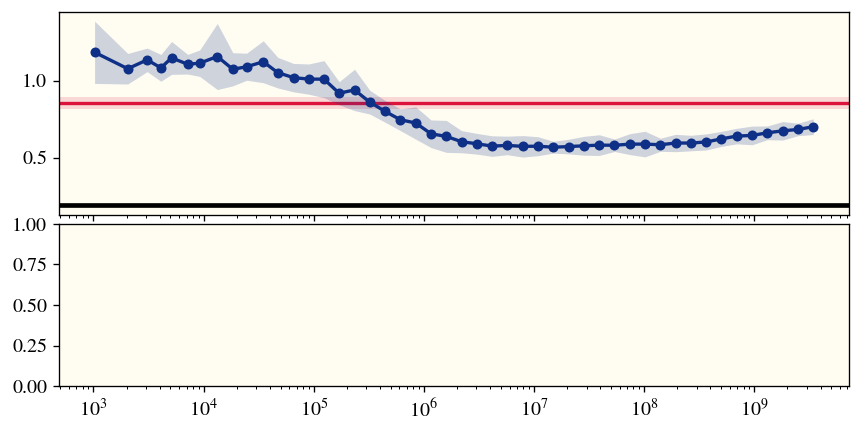

In [ ]:
FIGDIR = os.path.join(RESULTPATH, "figs")
os.makedirs(FIGDIR, exist_ok=True)

have = sorted({r["T"] for _, recs in runs for r in recs})
for T in CURVE_TS:
    if T not in have:
        print(f"no records at T={T}; the loaded runs have T = {have}")
        continue
    for label, recs in runs:            # what the pool alignment does, before it is hidden in a mean
        offs, base = pool_offsets(recs, T, SIDE, ALIGN, ALIGN_BASE)
        if len(offs) > 1:
            print(f"T={T} {label}: {SIDE.upper()} baseline dMMSE {base:.3f}; shifts "
                  + ", ".join(f"trial {t} {-d:+.3f}" for t, d in sorted(offs.items())))
    fig, axs = plot_with_probe(runs, T, SIDE, yscale=YSCALE, ylim=YLIM, band=SD_BAND,
                               legend_loc=LEGEND_LOC, xlabel=XLABEL, top_free=TOP_FREE, fontsize=FONTSIZE,
                               t_label=None, align=ALIGN, align_base=ALIGN_BASE, oracle_band=ORA_BAND,
                               groups=PROBE_SHOW, labels=PROBE_LABELS, probe_legend_loc=PROBE_LEGEND,
                               probe_ylim=PROBE_YLIM, height_ratio=HEIGHT_RATIO)
    stem = os.path.join(FIGDIR, f"ushape_rf_u_shape_fig2_{TAG}_T{T}_{SIDE}")
    fig.savefig(stem + ".pdf", bbox_inches="tight")
    fig.savefig(stem + ".png", dpi=200, bbox_inches="tight")
    print("saved", stem + ".{pdf,png}")
    plt.show()

T=8: phase boundaries at n = 1.73e+05, 1.31e+08 (20% of each family)


/tmp/ipykernel_1282/611594421.py:152: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


saved /content/drive/MyDrive/results/figs/transience_d4p5e0.05_M8192_b1024_w1.1_T8_ood.{pdf,png}


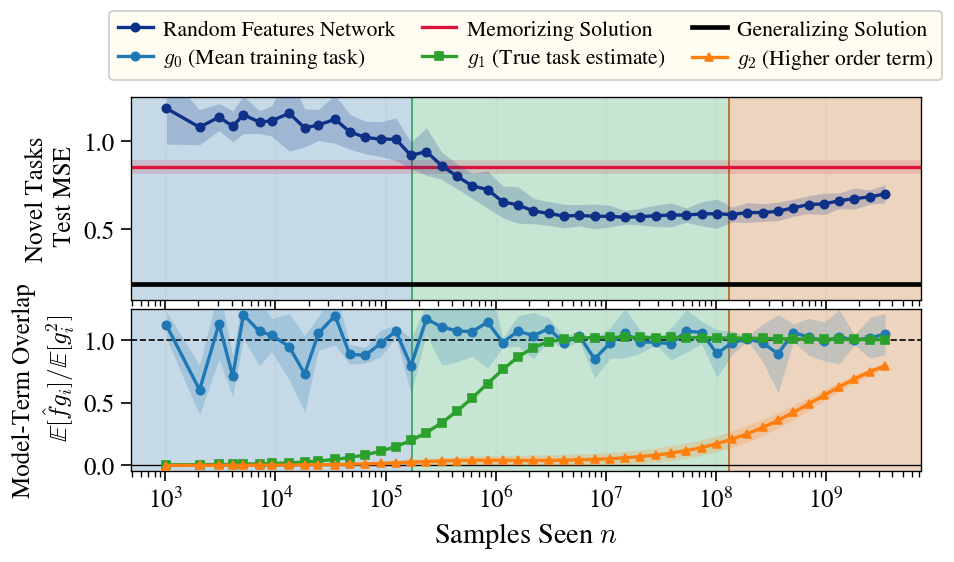

In [12]:
RUNS         = {"Random features\n network": None}   # label -> None (newest set of per-run checkpoints), a tag or
                                      #   part of one, or a path to a *_summary.pkl
CURVE_TS     = [8]                    # one figure per T
SIDE         = "ood"                  # the top panel's error: "ood" or "id"
YSCALE       = "linear"               # "log" as in fig 2
YLIM         = {"ood": (0.1, 1.25)}
SD_BAND      = True                   # +/- 1 standard deviation across trials (none with 1 trial)
ORA_BAND     = True                   # shade that spread on the oracle lines too
ALIGN        = None                   # put every trial on one pool's level before averaging: shift trial i
                                      #   by Delta_i = dMMSE_i - dMMSE_baseline (None = raw mean)
ALIGN_BASE   = "first"                # the baseline pool: the "first" trial, or the "mean" over trials
LEGEND_LOC   = "lower left"           # a lower legend sits just above an oracle line along the bottom
FONTSIZE     = 15                     # tick labels and legend; axis labels +2, the T label +6
T_LABEL      = True                   # the in-plot "T=..." label
TOP_FREE     = 0.25                   # keep this much of the top panel clear under the T label and legend
XLABEL       = r"Samples Seen $n$"
PROBE_SHOW   = ["mean  (q)", "ICL  (x y q)", "kappa_3  (y^2 x^3 q)"]
PROBE_LABELS = {"mean  (q)": r"$g_0$ (Mean training task)", "ICL  (x y q)": r"$g_1$ (True task estimate)",
                "kappa_3  (y^2 x^3 q)": r"$g_2$ (Higher order term)"} #$\kappa_3$
# PROBE_LABELS = {"mean  (q)": r"$\psi_1$ (Mean)", "ICL  (x y q)": r"$\psi_3$ (Covariance)",
#                 "kappa_3  (y^2 x^3 q)": r"$\psi_5$ (Skewness)"}
PROBE_LEGEND = "center left"
PROBE_YLIM   = (-0.05, 1.25)                   # e.g. (-0.05, 1.25); the noisy mean fraction can otherwise set it
HEIGHT_RATIO = 0.8                    # bottom panel height relative to the top

FIGDIR = os.path.join(RESULTPATH, "figs")
os.makedirs(FIGDIR, exist_ok=True)

have = sorted({r["T"] for _, recs in runs for r in recs})
for T in CURVE_TS:
    if T not in have:
        print(f"no records at T={T}; the loaded runs have T = {have}")
        continue
    for label, recs in runs:            # what the pool alignment does, before it is hidden in a mean
        offs, base = pool_offsets(recs, T, SIDE, ALIGN, ALIGN_BASE)
        if len(offs) > 1:
            print(f"T={T} {label}: {SIDE.upper()} baseline dMMSE {base:.3f}; shifts "
                  + ", ".join(f"trial {t} {-d:+.3f}" for t, d in sorted(offs.items())))
    fig, axs = plot_with_probe(runs, T, SIDE, yscale=YSCALE, ylim=YLIM, band=SD_BAND,
                               legend_loc=LEGEND_LOC, xlabel=XLABEL, top_free=TOP_FREE, fontsize=FONTSIZE,
                               t_label=None, align=ALIGN, align_base=ALIGN_BASE, oracle_band=ORA_BAND,
                               groups=PROBE_SHOW, labels=PROBE_LABELS, probe_legend_loc=PROBE_LEGEND,
                               probe_ylim=PROBE_YLIM, height_ratio=HEIGHT_RATIO)
    stem = os.path.join(FIGDIR, f"transience_{TAG}_T{T}_{SIDE}")
    fig.savefig(stem + ".pdf", bbox_inches="tight")
    fig.savefig(stem + ".png", dpi=200, bbox_inches="tight")
    print("saved", stem + ".{pdf,png}")
    plt.show()

In [ ]:
# Where each curve bottoms out and how far it climbs after (needs transience_utils from the clone).
try:
    import transience_utils as TU
    for label, records in runs:
        print(label)
        TU.summary_table(records, sorted({r["T"] for r in records}))
except ImportError as e:
    print(f"transience_utils not importable ({e}); skipping the summary table")

Random features
 network
   T   dMMSE  floor3  floor5   Ridge |     min       at n   final | dMMSE-min final-min
   8   0.854   0.608   0.792   0.189 |   0.568 14,963,712   0.702 |    +0.286    +0.134
